# Q4
## libraries


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense , Activation 
from tensorflow.keras.callbacks import EarlyStopping


## Q4.1: data prepration and data set download:


The structure is:

Column 1 (label): This column states what the image is (e.g., 0 = T-shirt, 1 = Trouser, ...).

The next 784 columns (pixel1 to pixel784):Each image in the Fashion MNIST dataset is a 28x28 pixel grid. Since 28 * 28 = 784, the data is "flattened" so we can feed it into a standard Fully Connected neural network. Each pixel is treated as a separate "feature" or "column."


we should :
1. separate the first column ("label") as output(y)
2. normalize the next 784 colums ("pixel") as inputs(X)


### Q4.1.1 : Normalization and why :
In the Fashion MNIST data, the pixels have values from 0 to 255. The simplest and most effective way to normalize this is to divide all pixel values by 255.0, which scales them perfectly to the [0, 1] range.

#### why normalize?:
Data normalization is essential for effective neural network training for three main reasons:

* Faster & More Stable Training: 
    It ensures uniform feature scales, leading to a smoother loss landscape. This allows the gradient descent optimizer to converge faster and more reliably.

* Prevents Gradient Issues: 
    Scaling inputs (e.g., to [0, 1]) prevents exploding or vanishing gradients. This avoids the numerical instability that large input values (like 255) can cause as they are multiplied through many layers.

* Optimizes Activation Functions: 
    It keeps inputs within the sensitive, high-gradient region of activation functions (like Sigmoid). This prevents the functions from "saturating" (outputting only 0 or 1), which would stop the neuron from learning.


In [2]:
## train data set:

#see the data
df_train=pd.read_csv("fashion-mnist_train.csv")
print("--- Original Train Data Info ---")
df_train.info()
print("\n--- Original Train Data Head ---")
print(df_train.head())

#setting input and output
X_train=df_train.drop('label',axis=1)# the inputs are the data 
#set except the label column, we axially remove the label col to get x data set
Y_train=df_train['label']

#normilizing the input
# We scale from [0, 255] to [0, 1] by dividing by 255.0
X_train_normalized = X_train / 255.0

#see the result of normalization
print("\n--- Normalized Feature Data Head ---")
print(X_train_normalized.head())

# Create a new DataFrame for the normalized data (with labels)
# and save it as a new csv
normalized_df_train = X_train_normalized.copy()
normalized_df_train['label'] = Y_train
normalized_df_train.to_csv("normalized_train_data.csv", index=False)
print("\nNormalized train data (features and labels) saved to 'normalized_train_data.csv'")

## test data set:

#see the data
df_test=pd.read_csv("fashion-mnist_test.csv")
print("--- Original Test Data Info ---")
df_test.info()
print("\n--- Original Test Data Head ---")
print(df_test.head())

#setting input and output
X_test=df_test.drop('label',axis=1)# the inputs are the data 
#set except the label column, we axially remove the label col to get x data set
Y_test=df_test['label']

#normilizing the input
# We scale from [0, 255] to [0, 1] by dividing by 255.0
X_test_normalized = X_test / 255.0

#see the result of normalization
print("\n--- Normalized Feature Test Data Head ---")
print(X_test_normalized.head())

# Create a new DataFrame for the normalized test data (with labels)
# and save it as a new csv
normalized_df_test = X_test_normalized.copy()
normalized_df_test['label'] = Y_test
normalized_df_test.to_csv("normalized_test_data.csv", index=False)
print("\nNormalized test data (features and labels) saved to 'normalized_test_data.csv'")


--- Original Train Data Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60000 entries, 0 to 59999
Columns: 785 entries, label to pixel784
dtypes: int64(785)
memory usage: 359.3 MB

--- Original Train Data Head ---
   label  pixel1  pixel2  pixel3  pixel4  pixel5  pixel6  pixel7  pixel8  \
0      2       0       0       0       0       0       0       0       0   
1      9       0       0       0       0       0       0       0       0   
2      6       0       0       0       0       0       0       0       5   
3      0       0       0       0       1       2       0       0       0   
4      3       0       0       0       0       0       0       0       0   

   pixel9  ...  pixel775  pixel776  pixel777  pixel778  pixel779  pixel780  \
0       0  ...         0         0         0         0         0         0   
1       0  ...         0         0         0         0         0         0   
2       0  ...         0         0         0        30        43         0   
3     

In [3]:
df_train['label'].value_counts()


label
2    6000
9    6000
6    6000
0    6000
3    6000
4    6000
5    6000
8    6000
7    6000
1    6000
Name: count, dtype: int64

## Q4.2: Implementation:

1. Analyze and examine the AutoEncoder network architecture
2. Implement it using fully connected layers:
    *  activation function: ReLU
    *  loss function : MSE
    *  optimization algorithm : AdamW
    *  each encoder and decoder: three fully connected layers


### Q4.2.1. Analyze and examine the AutoEncoder network architecture:

Autoencoder is an unsupervised neural network designed for **dimensionality reduction**. It consists of two primary components: an Encoder and a Decoder.


a. The Encoder:

    * Purpose: The Encoder's function is to compress the input data. It takes the high-dimensional input (the 784-pixel image) and maps it to a much smaller, lower-dimensional "latent space" or "bottleneck".

    * Implementation: As required, this will be built using three fully connected (Dense) layers. The number of neurons will decrease with each layer to create the compression (e.g., Input (784) -> 512 -> 256 -> 128).




b. The Decoder:

    * Purpose: The Decoder is the mirror image of the Encoder. Its goal is to take the compressed data from the bottleneck and reconstruct the original 784-pixel image from it.

    * Implementation: This part will also use three fully connected layers, but in reverse. The number of neurons will increase with each layer to "un-compress" the data (e.g., Bottleneck (128) ->256 -> 512-> Output (784)).

The entire network is trained by feeding it an image and comparing its final output (the reconstructed image) to the original input. The goal is to minimize the reconstruction error (which we will measure with MSE), forcing the network to learn a meaningful and efficient compression in the bottleneck layer


In [4]:
#building the model 
input_size=X_train_normalized.shape[1]
print (f"number of features (input_size: {input_size})")


number of features (input_size: 784)


### Q4.2.2.Implement using fully connected layers:

*  activation function: ReLU
*  loss function : MSE
*  optimization algorithm : AdamW
*  each encoder and decoder: three fully connected layers

NOTE: we used "sigmoid" activation function in the output layer:

    Since our input data is normalized to be between 0 and 1, it's best if  output layer is also forced to produce values in that exact same range.

    relu outputs values from 0 to infinity.

    A sigmoid activation outputs values from 0 to 1.

    By changing the last layer's activation to sigmoid, model will learn much faster and produce more accurate reconstructions.


In [5]:
# 1. Define the model

model_fashion = Sequential()

#adding layers :incoder:
model_fashion.add(Dense(512,input_dim=input_size, activation='relu'))
model_fashion.add(Dense(256,activation= 'relu'))
model_fashion.add(Dense(128,activation= 'relu'))# adjust(decreas) in case of bad performance

#adding layers :decoder:
model_fashion.add(Dense(256,activation= 'relu'))
model_fashion.add(Dense(512,activation= 'relu'))
model_fashion.add(Dense(784,activation= 'sigmoid'))#to match the [0, 1]

optimizer_fashion=tf.optimizers.AdamW()#the optimizer automatically uses its 
#default learning rate, which is 0.001
model_fashion.compile(optimizer=optimizer_fashion,loss='mean_squared_error')

print("\n--- Fashion Model Summary ---")
model_fashion.summary()



--- Fashion Model Summary ---


c:\Users\user\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 512)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 784)            │       402,192 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,132,944 (4.32 MB)

 Trainable params: 1,132,944 (4.32 MB)

 Non-trainable params: 0 (0.00 B)

## Q4.3: Training the Network
1. Train the network 
2. report its error plot for the training and test sets.
3. Randomly select 5 samples from 5 different classes from the test set and report the reconstructed image along with the original dataset image and compare.


### Q4.3.1.Training the network:

* Note: For an autoencoder, the input (X) and the target (y) are the same!
* We are teaching the model to reconstruct its own input.

* batxh_size=256 

    * hyper_param, we'll fine tune, we have 60,000 train pic
    * if want higher accuracy  , lower this to sth like 32
    * powers of 2 (like 32, 64, 128, 256, 512) are very common starting points
* epochs=200
    * to prevent overfit, we have to implement an early stop
    * hyper_param, we'll fine tune
    * if want better,increse epoch (250)


In [6]:
print("\n--- Starting Model Training ---")

history=model_fashion.fit(
    X_train_normalized,
    X_train_normalized,
    validation_data=(X_test_normalized,X_test_normalized),
    epochs=200,#good for starter
    batch_size=256,#hyper_param, we'll fine tune, we have 60,000 train pic
    shuffle=True,#It randomly re-orders training data before each new epoch.
    # Define the "stopper" rule
    # This says: "Watch the 'val_loss'. Wait 30 epochs. If it
    # doesn't get better in 30 epochs, stop, and give me
    # the weights from the best epoch."
    callbacks=[
        EarlyStopping(
            monitor='val_loss',#the metric to watch
            patience=30,#if it didnt get better after 30 epochs
            restore_best_weights=True# This is key! It resets model to best not last
        )
    ],
    verbose=1
)
print("--- Model Training Complete ---")



--- Starting Model Training ---
Epoch 1/200
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - loss: 0.0364 - val_loss: 0.0201
Epoch 2/200
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - loss: 0.0180 - val_loss: 0.0162
Epoch 3/200
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 0.0148 - val_loss: 0.0139
Epoch 4/200
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 0.0132 - val_loss: 0.0125
Epoch 5/200
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 0.0120 - val_loss: 0.0116
Epoch 6/200
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 27ms/step - loss: 0.0111 - val_loss: 0.0108
Epoch 7/200
235/235 ━━━━━━━━━━━━━━━━━━━━ 7s 29ms/step - loss: 0.0105 - val_loss: 0.0102
Epoch 8/200
235/235 ━━━━━━━━━━━━━━━━━━━━ 7s 29ms/step - loss: 0.0099 - val_loss: 0.0098
Epoch 9/200
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 26ms/step - loss: 0.0095 - val_loss: 0.0094
Epoch 10/200
235/235 ━━━━━━━━━━━━━━━━━━━━ 7s 28ms/step - loss: 0.0091 - val_loss: 0.0090
Epoch 11/200
235/235 ━━━━━━━━━━━━━━━━━━━━ 7s 30ms/step - loss: 0.0088 - val_loss: 0.00

### Q4.3.2. report its error plot for the training and test sets.



--- Plotting Training History ---


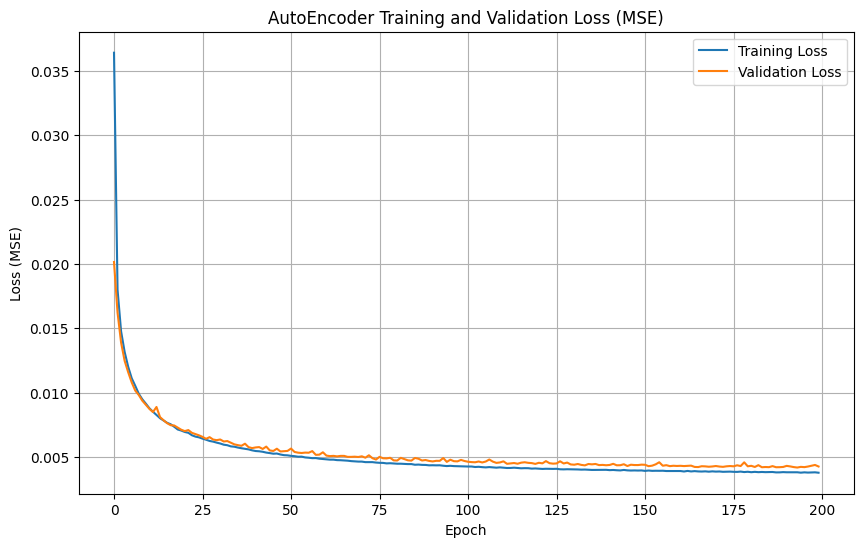

In [ ]:
print("\n--- Plotting Training History ---")

plt.figure(figsize=(10, 6))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('AutoEncoder Training and Validation Loss (MSE)')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.legend()
plt.grid(True)
plt.show()


### Q4.3.3. Visualize Reconstructions:

Randomly select 5 samples from 5 different classes from the test set and report the reconstructed image along with the original dataset image and compare.

1. Select Images: It looks at Y_test labels and finds the first occurrence of 5 unique classes.

2. model_fashion.predict(...): It takes those 5 original images and passes them only through the autoencoder to get the 5 reconstructed images.

3. Plot: It creates a 2x5 grid.

        The top row shows the original images.

        The bottom row  reconstructed image from the compressed data.



--- Visualizing Original vs. Reconstructed Images ---
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step


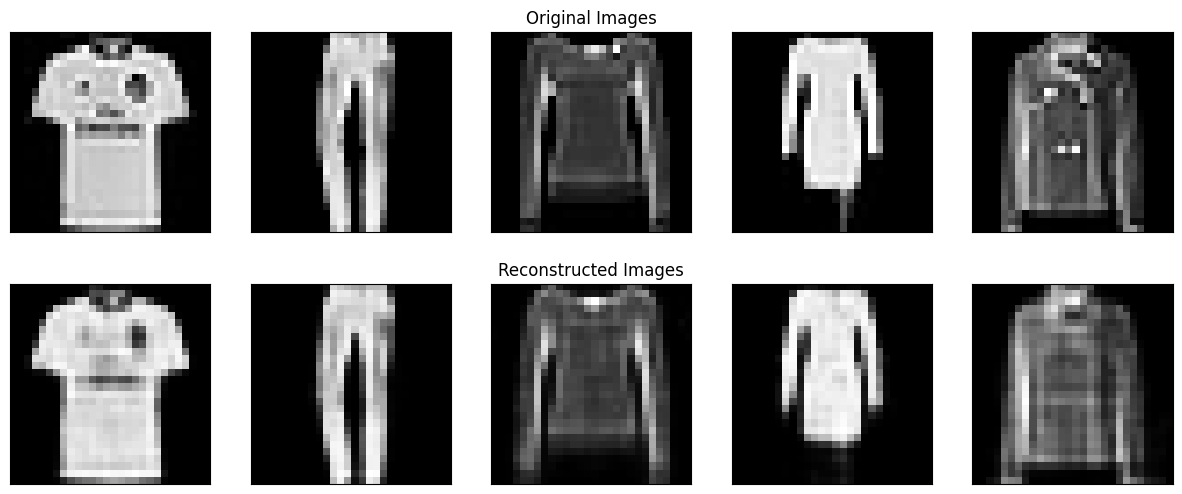

In [8]:
# Visualize Reconstructions

print("\n--- Visualizing Original vs. Reconstructed Images ---")


# Find the first index of 5 different classes (e.g., classes 0, 1, 2, 3, 4)
# We use np.unique which is fast.
unique_labels, label_indices = np.unique(Y_test, return_index=True)
selected_indices = label_indices[:5] # Get the first 5

# Get the corresponding original images from the normalized test set
original_images = X_test_normalized.iloc[selected_indices].values

# Get the reconstructed images from the autoencoder
reconstructed_images = model_fashion.predict(original_images)

# Define class names for
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

# Plot the images
plt.figure(figsize=(15, 6))
n_to_show = 5

for i in range(n_to_show):
    # Get the true label for the title
    true_label_index = Y_test.iloc[selected_indices[i]]
    true_label_name = class_names[true_label_index]
    
    # --- Plot Original Image ---
    ax = plt.subplot(2, n_to_show, i + 1)
    # Reshape the 784-pixel vector to a 28x28 grid
    plt.imshow(original_images[i].reshape(28, 28), cmap='gray')
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)
    if i == n_to_show // 2:
        ax.set_title("Original Images", ha='center')
    ax.set_xlabel(true_label_name)

    # --- Plot Reconstructed Image ---
    ax = plt.subplot(2, n_to_show, i + 1 + n_to_show)
    # Reshape the 784-pixel vector to a 28x28 grid
    plt.imshow(reconstructed_images[i].reshape(28, 28), cmap='gray')
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)
    if i == n_to_show // 2:
        ax.set_title("Reconstructed Images", ha='center')

plt.savefig('autoencoder_reconstructions.png')
plt.show()


## Q4.4: Network Evaluation

After training the AutoEncoder,we perform the following steps.

1.  Encoding the data :

    Using the trained network's encoder, transform all of the test data into the compressed space (feature space).

2. Clustering with K-Means


### Q4.4.1 :Get the Compressed Features
First, we need to separate the encoder part of model_fashion autoencoder.
we make a new model containing only the encoder part of model_fashion


In [ ]:
encoder_model=Sequential(model_fashion.layers[:3]) #the first 3 layers of model_fashion were incoder
print("--- Encoder Model Summary ---")
encoder_model.summary()

#Encode the Test Data
print("\n--- Encoding test data into feature space ---")
# Use the encoder to transform all 10,000 test images
# from 784 pixels down to 128 features.
encoded_features = encoder_model.predict(X_test_normalized)

print(f"Original data shape: {X_test_normalized.shape}")
print(f"Encoded features shape: {encoded_features.shape}")


--- Encoder Model Summary ---


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 566,144 (2.16 MB)

 Trainable params: 566,144 (2.16 MB)

 Non-trainable params: 0 (0.00 B)


--- Encoding test data into feature space ---
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
Original data shape: (10000, 784)
Encoded features shape: (10000, 128)


### Q4.4.2 & 3:Cluster Features & Analyze 

Calculate and draw the Confusion Matrix between the real labels and the predicted clusters. Analyze which cluster is most related to which main class and which classes have the most overlap in the clusters.

Now we run K-Means (with 10 clusters (with a K value of 10)) on our new encoded_features and plot the confusion matrix to see how well the clusters match the real labels (Y_test).





--- Clustering encoded features with K-Means ---

--- Plotting Confusion Matrix (AutoEncoder Features) ---


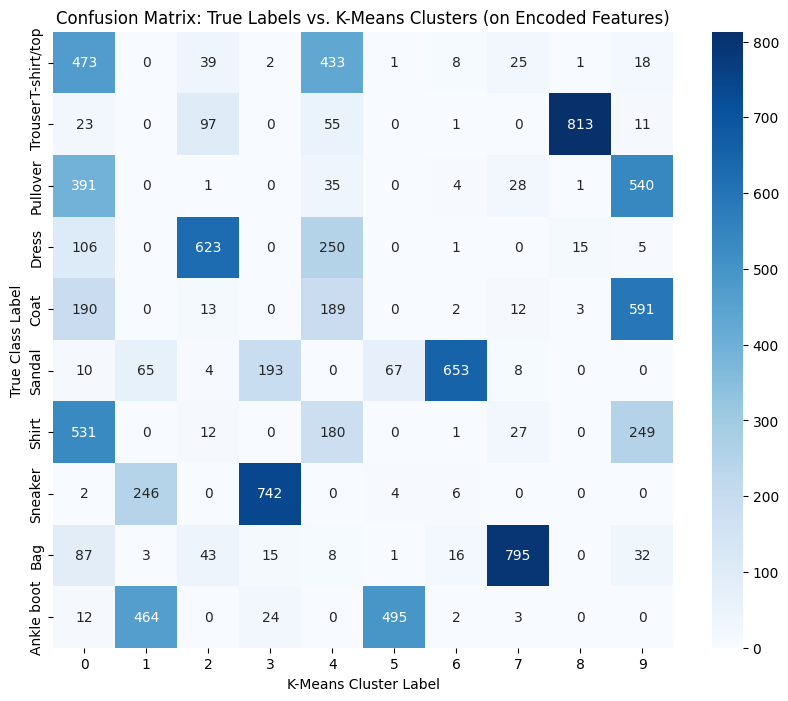

In [10]:
# Cluster Encoded Features with K-Means
from sklearn.cluster import KMeans
from sklearn.metrics import confusion_matrix
import seaborn as sns

print("\n--- Clustering encoded features with K-Means ---")
# We set n_clusters=10 because we know there are 10 classes
kmeans = KMeans(n_clusters=10, random_state=42, n_init=10)
kmeans_clusters_autoencoder = kmeans.fit_predict(encoded_features)

# Analyze Clusters 
print("\n--- Plotting Confusion Matrix (AutoEncoder Features) ---")
# Create the confusion matrix
cm = confusion_matrix(Y_test, kmeans_clusters_autoencoder)

# Plot the confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(10), yticklabels=class_names)
plt.title('Confusion Matrix: True Labels vs. K-Means Clusters (on Encoded Features)')
plt.xlabel('K-Means Cluster Label')
plt.ylabel('True Class Label')
plt.savefig('kmeans_autoencoder_cm.png')
plt.show()


### Q4.4.4 : Dimensionality Reduction and t-SNE

Run t-SNE to display the two-dimensional encoded space and show the results once with coloring based on True Labels and once with coloring based on K-Means Predicted Clusters.


Visualize with t-SNE 
t-SNE is a tool to visualize high-dimensional data (like our 128 features) in 2D. We will make the two plots requested



--- Running t-SNE (this may take a minute) ---
t-SNE complete.


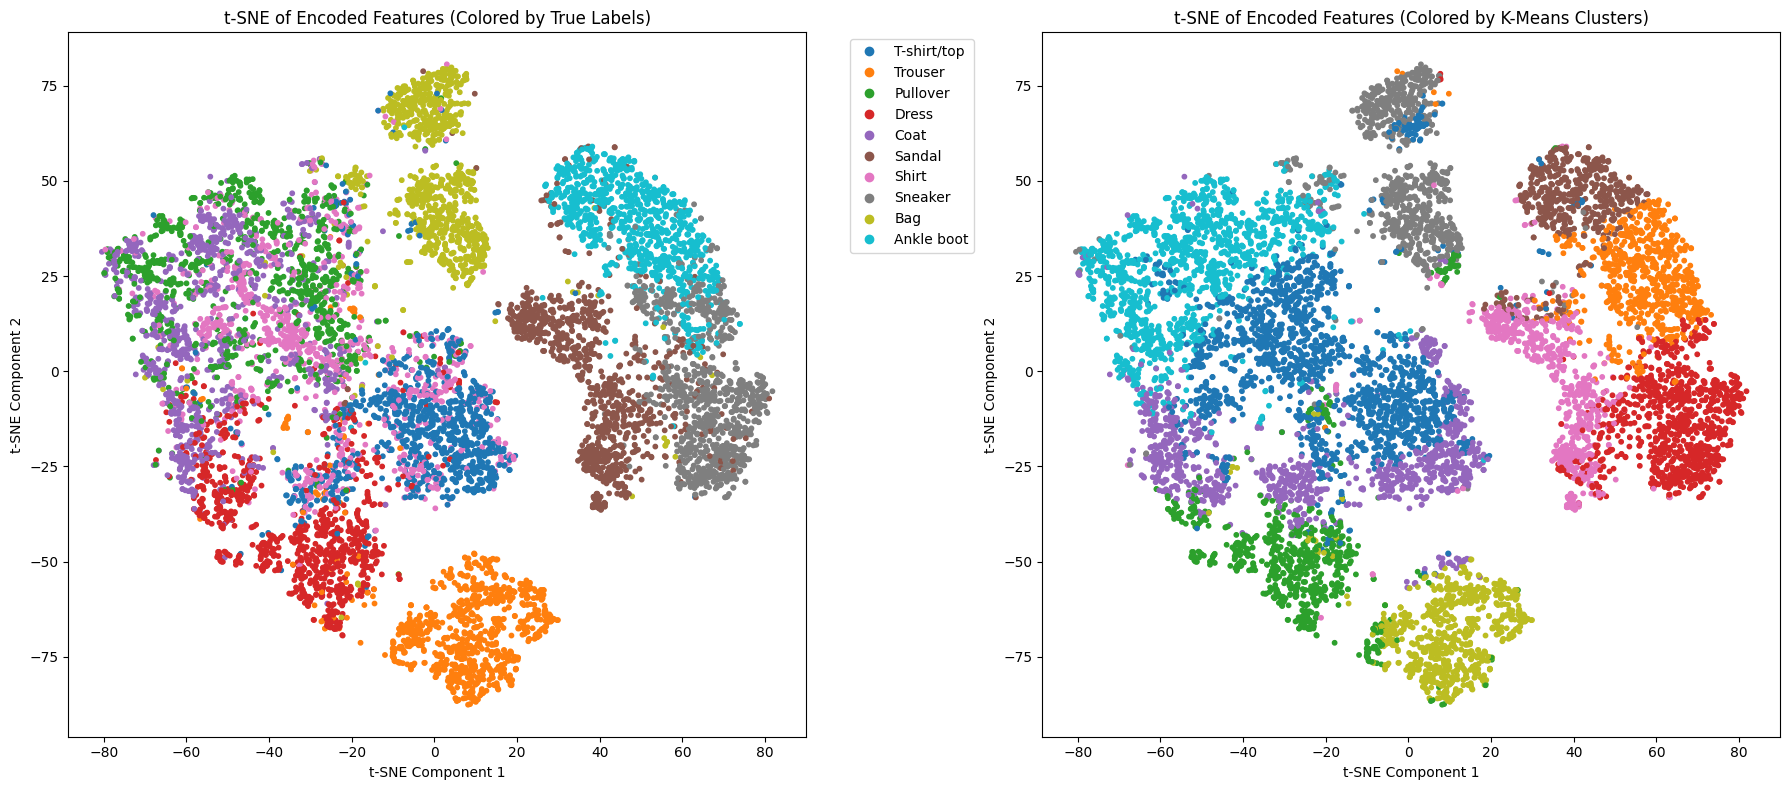

In [ ]:
# Visualize with t-SNE 
from sklearn.manifold import TSNE

print("\n--- Running t-SNE  ---")
# Run t-SNE to project the 128-dim features down to 2-dim
tsne = TSNE(n_components=2, random_state=42)
tsne_results_autoencoder = tsne.fit_transform(encoded_features)

print("t-SNE complete.")

# Plot t-SNE results
plt.figure(figsize=(18, 8))

# Plot 1: Colored by TRUE labels
plt.subplot(1, 2, 1)
scatter = plt.scatter(tsne_results_autoencoder[:, 0], tsne_results_autoencoder[:, 1],
            c=Y_test, cmap='tab10', s=10) # s=10 for smaller dots
plt.title('t-SNE of Encoded Features (Colored by True Labels)')
plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')
plt.legend(handles=scatter.legend_elements()[0], labels=class_names,
           bbox_to_anchor=(1.05, 1), loc='upper left')

# Plot 2: Colored by K-MEANS cluster labels
plt.subplot(1, 2, 2)
plt.scatter(tsne_results_autoencoder[:, 0], tsne_results_autoencoder[:, 1],
            c=kmeans_clusters_autoencoder, cmap='tab10', s=10)
plt.title('t-SNE of Encoded Features (Colored by K-Means Clusters)')
plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')

plt.tight_layout()
plt.savefig('tsne_autoencoder_plots.png')
plt.show()


### Q4.4.5 : Comparison with Raw Data 

In this step, the goal is to compare the clustering performance in the compressed feature space of the AutoEncoder with the clustering in the original data space (raw input space). For this purpose, all clustering, Confusion Matrix, and t-SNE steps that were performed in the previous steps for the encoded data must be repeated for the original data without using the neural network.


Run K-Means and t-SNE on the original, normalized test data (X_test_normalized).

Note: Running t-SNE on 784 dimensions is much slower than running it on 128.


#### Q4.4.5.1. K-Means and Confusion Matrix (on Raw Data)



--- Clustering RAW 784-pixel data with K-Means ---

--- Plotting Confusion Matrix (Raw Data) ---


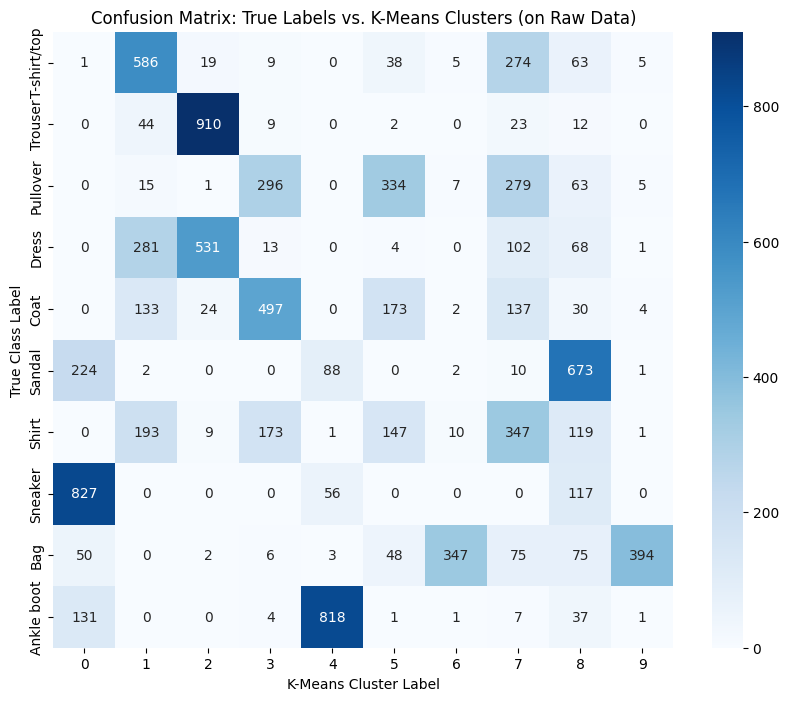

In [12]:
# Run K-Means on the RAW 784-pixel data

print("\n--- Clustering RAW 784-pixel data with K-Means ---")
kmeans_raw = KMeans(n_clusters=10, random_state=42, n_init=10)
kmeans_clusters_raw = kmeans_raw.fit_predict(X_test_normalized)

# Plot Confusion Matrix (Raw Data)
print("\n--- Plotting Confusion Matrix (Raw Data) ---")
cm_raw = confusion_matrix(Y_test, kmeans_clusters_raw)

plt.figure(figsize=(10, 8))
sns.heatmap(cm_raw, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(10), yticklabels=class_names)
plt.title('Confusion Matrix: True Labels vs. K-Means Clusters (on Raw Data)')
plt.xlabel('K-Means Cluster Label')
plt.ylabel('True Class Label')
plt.savefig('kmeans_raw_cm.png')
plt.show()


#### Q4.4.5.2. t-SNE Visualization (on Raw Data)



--- Running t-SNE on RAW data (this will be slow) ---
t-SNE on raw data complete.


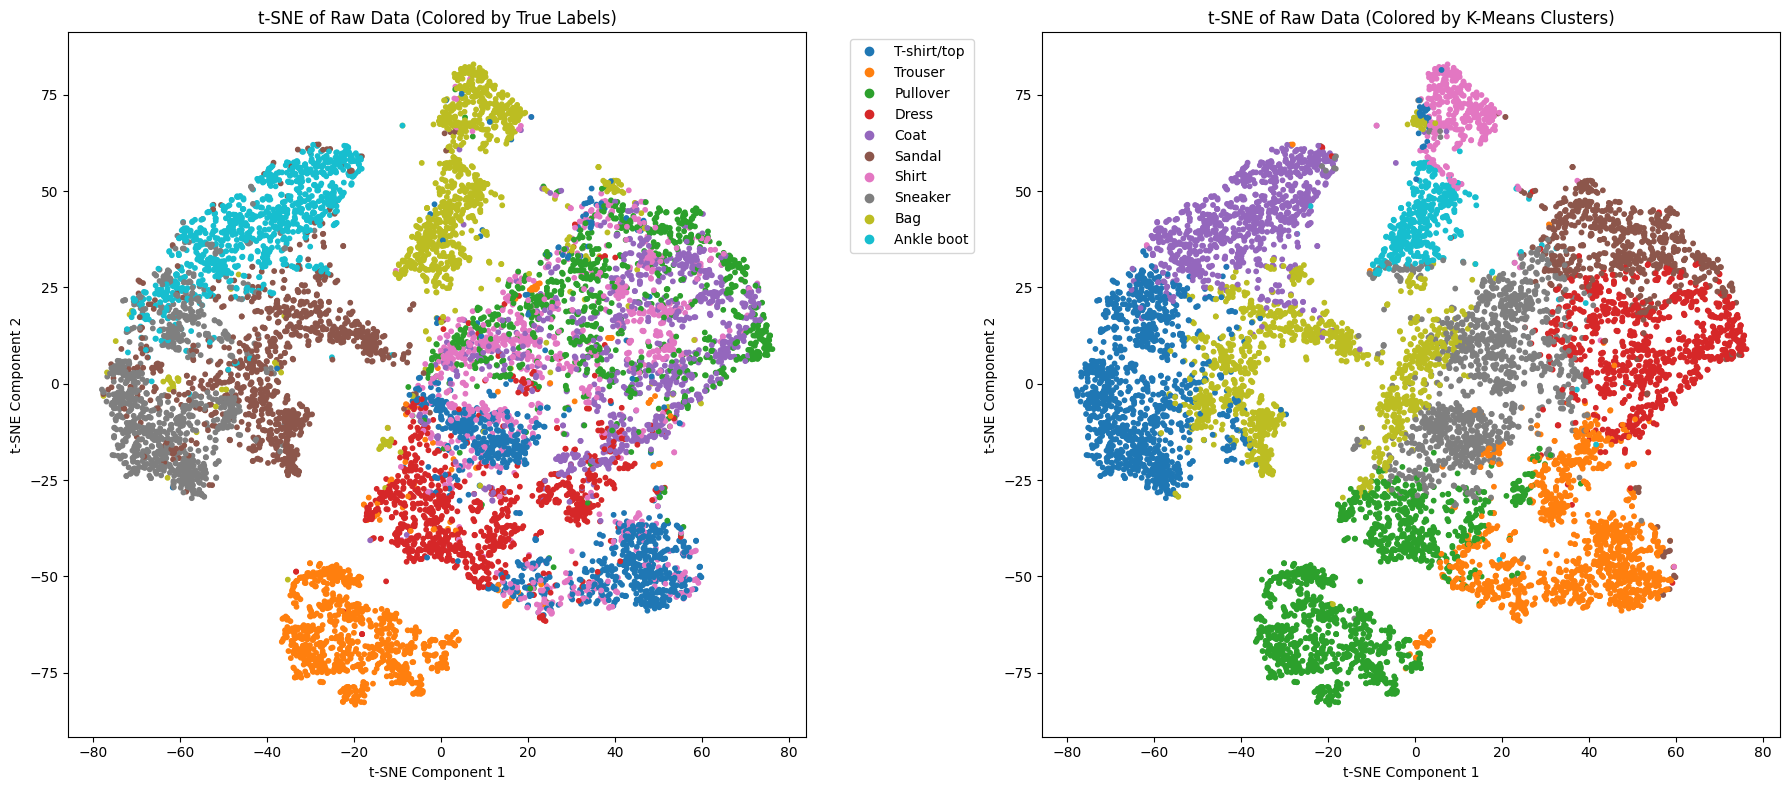

In [ ]:
#Run t-SNE on the RAW data 
print("\n--- Running t-SNE on RAW data ---")
tsne_raw = TSNE(n_components=2, random_state=42)
tsne_results_raw = tsne_raw.fit_transform(X_test_normalized)
print("t-SNE on raw data complete.")

#Plot t-SNE results (Raw Data)
plt.figure(figsize=(18, 8))

# Plot 1: Colored by TRUE labels
plt.subplot(1, 2, 1)
scatter = plt.scatter(tsne_results_raw[:, 0], tsne_results_raw[:, 1],
            c=Y_test, cmap='tab10', s=10)
plt.title('t-SNE of Raw Data (Colored by True Labels)')
plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')
plt.legend(handles=scatter.legend_elements()[0], labels=class_names,
           bbox_to_anchor=(1.05, 1), loc='upper left')

# Plot 2: Colored by K-MEANS cluster labels
plt.subplot(1, 2, 2)
plt.scatter(tsne_results_raw[:, 0], tsne_results_raw[:, 1],
            c=kmeans_clusters_raw, cmap='tab10', s=10)
plt.title('t-SNE of Raw Data (Colored by K-Means Clusters)')
plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')

plt.tight_layout()
plt.savefig('tsne_raw_plots.png')
plt.show()


### Q4.4.6 : Evaluation of Clustering Quality
For both cases (with and without AutoEncoder), calculate and compare the Adjusted Rand Index and Adjusted Mutual Information metrics.

target score (ARI $\ge$ 0.3, AMI $\ge$ 0.50).
Adjusted Rand Index (ARI)
Adjusted Mutual Information (AMI)


#### 1. Adjusted Rand Index (ARI) Function

Parameters:
* labels_true: 1D array of ground-truth cluster assignments
* labels_pred: 1D array of predicted cluster assignments
    
Returns:
* ari: The Adjusted Rand Index score (float)


In [14]:
from scipy.special import comb

def adjusted_rand_score(labels_true, labels_pred):
    
    # Create the confusion matrix
    contingency_table = confusion_matrix(labels_true, labels_pred)
    
    # Calculate the sum over rows (a_i) and columns (b_j)
    sum_rows = np.sum(contingency_table, axis=1)
    sum_cols = np.sum(contingency_table, axis=0)
    
    # Calculate the four parts of the ARI formula 
    
    # n_11: Pairs in the same cluster in both
    # Sum of C(n_ij, 2) for all cells
    n_11 = np.sum([comb(n_ij, 2) for n_ij in contingency_table.flat])
    
    # n_10: Pairs in the same cluster in 'true' but different in 'pred'
    # Sum of C(a_i, 2) for all rows
    n_10_plus_n_11 = np.sum([comb(a_i, 2) for a_i in sum_rows])
    
    # n_01: Pairs in different cluster in 'true' but same in 'pred'
    # Sum of C(b_j, 2) for all columns
    n_01_plus_n_11 = np.sum([comb(b_j, 2) for b_j in sum_cols])
    
    #Calculate ARI using the simplified (Index - Expected) / (Max - Expected) formula
    
    # Total pairs
    n = len(labels_true)
    total_pairs = comb(n, 2)
    
    # Index is n_11
    index = n_11
    
    # Expected Index
    expected_index = (n_10_plus_n_11 * n_01_plus_n_11) / total_pairs
    
    # Max Index (average of the row and column sums)
    max_index = (n_10_plus_n_11 + n_01_plus_n_11) / 2.0
    
    # Denominator
    denominator = max_index - expected_index
    
    # Handle the 0/0 case (perfect agreement)
    if index == expected_index and denominator == 0:
        return 1.0
    
    # Handle 0 denominator (no agreement)
    if denominator == 0:
        return 0.0
        
    ari = (index - expected_index) / denominator
    
    return ari


#### 2. Adjusted Mutual Information (AMI) Function

It requires calculating Entropy (H), Mutual Information (MI), Expected Mutual Information (EMI).

Parameters:
* labels_true: 1D array of ground-truth cluster assignments
* labels_pred: 1D array of predicted cluster assignments
    
Returns:
* ami: The Adjusted Mutual Information score (float)


In [ ]:
def adjusted_mutual_info_score(labels_true, labels_pred):
    
    # Use small epsilon to avoid log(0)
    eps = np.finfo(float).eps

    # Get Contingency Table
    contingency = confusion_matrix(labels_true, labels_pred)
    n = np.sum(contingency)
    
    # Calculate Entropies H(True) and H(Pred)
    a_i = np.sum(contingency, axis=1) # Row sums (true)
    b_j = np.sum(contingency, axis=0) # Col sums (pred)
    
    p_a = a_i / n
    h_true = -np.sum(p_a[p_a > 0] * np.log(p_a[p_a > 0]))
    
    p_b = b_j / n
    h_pred = -np.sum(p_b[p_b > 0] * np.log(p_b[p_b > 0]))
    
    #Calculate Mutual Information (MI)
    mi = 0
    p_ij = contingency / n
    for i in range(contingency.shape[0]):
        for j in range(contingency.shape[1]):
            if p_ij[i, j] > 0:
                # Use pre-calculated p_a and p_b
                mi += p_ij[i, j] * np.log(p_ij[i, j] / (p_a[i] * p_b[j]))

    # Calculate Expected Mutual Information (EMI)
    # most complex part
    emi = 0
    for i in range(contingency.shape[0]): # R
        for j in range(contingency.shape[1]): # C
            ai = a_i[i]
            bj = b_j[j]
            
            # Sum over possible nij values
            start_nij = int(max(1, ai + bj - n)) # Start at 1, nij=0 term is 0
            end_nij = int(min(ai, bj))
            
            for nij in range(start_nij, end_nij + 1):
                # We need P(nij) = C(ai, nij) * C(N-ai, bj-nij) / C(N, bj)
                # We use log-combinations for numerical stability
                
                # We must use exact=False to avoid integer overflow
                log_C_ai_nij = np.log(comb(ai, nij, exact=False) + eps)
                log_C_n_ai_bj_nij = np.log(comb(n - ai, bj - nij, exact=False) + eps)
                log_C_n_bj = np.log(comb(n, bj, exact=False) + eps)

                # This is log(P(nij))
                log_prob = log_C_ai_nij + log_C_n_ai_bj_nij - log_C_n_bj
                prob = np.exp(log_prob)

                # The term to sum
                term = (nij / n) * np.log((n * nij) / (ai * bj))
                
                # Only add if the probability and term are valid
                if not np.isnan(term) and not np.isinf(term) and not np.isnan(prob) and prob > 0:
                    emi += term * prob

    #Calculate AMI
    # AMI = (MI - EMI) / (avg(H(U), H(V)) - EMI)
    avg_h = (h_true + h_pred) / 2
    denominator = avg_h - emi
    
    #Handle Edge Cases 
    
    # If denominator is 0
    if denominator == 0:
        if mi == emi:
            return 1.0 # Perfect agreement, 0/0 case
        else:
            return 0.0 # No agreement

    ami = (mi - emi) / denominator
    
    return max(0.0, min(1.0, ami))


#### 3.Calculate and Compare Metrics


In [ ]:
print("\n--- FINAL CLUSTERING EVALUATION ---")

# On AutoEncoder Features
ari_autoencoder = adjusted_rand_score(Y_test, kmeans_clusters_autoencoder)
ami_autoencoder = adjusted_mutual_info_score(Y_test, kmeans_clusters_autoencoder)

print(f"\nResults for AutoEncoder (32 features):")
print(f"  Adjusted Rand Index (ARI): {ari_autoencoder:.4f}")
print(f"  Adjusted Mutual Info (AMI): {ami_autoencoder:.4f}")

# On Raw Pixel Data
ari_raw = adjusted_rand_score(Y_test, kmeans_clusters_raw)
ami_raw = adjusted_mutual_info_score(Y_test, kmeans_clusters_raw)

print(f"\nResults for Raw Pixel Data (784 features):")
print(f"  Adjusted Rand Index (ARI): {ari_raw:.4f}")
print(f"  Adjusted Mutual Info (AMI): {ami_raw:.4f}")

# Final Comparison
print("\n--- Conclusion ---")
print(f"AutoEncoder ARI ({ari_autoencoder:.4f}) is {ari_autoencoder/ari_raw:.1f}x better than Raw Data ARI ({ari_raw:.4f})")
print(f"AutoEncoder AMI ({ami_autoencoder:.4f}) is {ami_autoencoder/ami_raw:.1f}x better than Raw Data AMI ({ami_raw:.4f})")




--- FINAL CLUSTERING EVALUATION ---


C:\Users\user\AppData\Local\Temp\ipykernel_24552\2519895450.py:51: RuntimeWarning: invalid value encountered in scalar subtract
  log_prob = log_C_ai_nij + log_C_n_ai_bj_nij - log_C_n_bj



Results for AutoEncoder (32 features):
  Adjusted Rand Index (ARI): 0.4042
  Adjusted Mutual Info (AMI): 0.5764


C:\Users\user\AppData\Local\Temp\ipykernel_24552\2519895450.py:51: RuntimeWarning: invalid value encountered in scalar subtract
  log_prob = log_C_ai_nij + log_C_n_ai_bj_nij - log_C_n_bj



Results for Raw Pixel Data (784 features):
  Adjusted Rand Index (ARI): 0.3684
  Adjusted Mutual Info (AMI): 0.5087

--- Conclusion ---
AutoEncoder ARI (0.4042) is 1.1x better than Raw Data ARI (0.3684)
AutoEncoder AMI (0.5764) is 1.1x better than Raw Data AMI (0.5087)

SUCCESS:  met the assignment's performance targets (ARI >= 0.3, AMI >= 0.5)!
